# Notebook 03 — Convolutional Autoencoder for Feature Extraction

This notebook trains a **Convolutional Autoencoder (CAE)** to learn compact spatial representations from SAR images.

**Stages:**
1. Model architecture overview
2. Training with MSE reconstruction loss
3. Loss curve visualization
4. Reconstructed image comparison
5. Latent space visualization
6. Save encoder weights

## Step 1: Imports & Setup

In [1]:
import os
import sys
sys.path.insert(0, '..')

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from dataset import Sen1FloodsDataset, get_train_val_test_splits
from models import ConvAutoencoder
from utils import set_seed, load_config

plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor'] = '#161b22'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

config = load_config('../config.json')
set_seed(config['training']['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


Using device: cpu


## Step 2: Model Architecture

In [2]:
# Display the model architecture
model = ConvAutoencoder(dropout_rate=config['model']['dropout_rate']).to(device)
print('=== ConvAutoencoder Architecture ===')
print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')


=== ConvAutoencoder Architecture ===
ConvAutoencoder(
  (encoder): SpatialEncoder(
    (encoder): Sequential(
      (0): Conv2d(2, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (8): ReLU(inplace=True)
      (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (11): ReLU(inplace=True)
   

## Step 3: Data Loaders

In [3]:
S1_DIR = '../' + config['data']['s1_dir']
LABEL_DIR = '../' + config['data']['label_dir']
TARGET_SIZE = tuple(config['data']['target_size'])

s1_files = sorted([f for f in os.listdir(S1_DIR) if f.endswith('.tif')])
label_files = sorted([f for f in os.listdir(LABEL_DIR) if f.endswith('.tif')])
file_pairs = list(zip(
    [os.path.join(S1_DIR, f) for f in s1_files],
    [os.path.join(LABEL_DIR, f) for f in label_files]
))

train_idx, val_idx, test_idx = get_train_val_test_splits(len(file_pairs), config['data']['split_ratio'])
train_pairs = [file_pairs[i] for i in train_idx]
val_pairs = [file_pairs[i] for i in val_idx]

train_dataset = Sen1FloodsDataset(train_pairs, target_size=TARGET_SIZE)
val_dataset   = Sen1FloodsDataset(val_pairs, target_size=TARGET_SIZE)
train_loader = DataLoader(train_dataset, batch_size=config['training']['batch_size'],
                          shuffle=True, num_workers=config['data']['num_workers'])
val_loader   = DataLoader(val_dataset, batch_size=config['training']['batch_size'],
                          shuffle=False, num_workers=config['data']['num_workers'])

print(f'Train: {len(train_dataset)} | Val: {len(val_dataset)} samples')


Train: 28 | Val: 6 samples


## Step 4: Train the Autoencoder

In [4]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=config['training']['autoencoder_lr'])
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

os.makedirs('../models', exist_ok=True)

train_losses, val_losses = [], []
best_val_loss = float('inf')
patience_counter = 0
PATIENCE = config['training']['early_stopping_patience']
NUM_EPOCHS = config['training']['autoencoder_epochs']

print(f'Training for up to {NUM_EPOCHS} epochs...')

for epoch in range(NUM_EPOCHS):
    # Training
    model.train()
    train_loss = 0.0
    for data, _ in train_loader:
        data = data.to(device)
        optimizer.zero_grad()
        reconstructed, _ = model(data)
        loss = criterion(reconstructed, data)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * data.size(0)
    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for data, _ in val_loader:
            data = data.to(device)
            reconstructed, _ = model(data)
            loss = criterion(reconstructed, data)
            val_loss += loss.item() * data.size(0)
    val_loss /= len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    scheduler.step(val_loss)

    print(f'Epoch [{epoch+1}/{NUM_EPOCHS}] Train Loss: {train_loss:.5f} | Val Loss: {val_loss:.5f}')

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), '../models/best_autoencoder.pth')
        torch.save(model.encoder.encoder.state_dict(), '../models/encoder.pth')
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}')
            break

print(f'\nBest val loss: {best_val_loss:.5f}')
print('Saved: ../models/best_autoencoder.pth & ../models/encoder.pth')


Training for up to 15 epochs...


Epoch [1/15] Train Loss: 0.03837 | Val Loss: 0.03915


Epoch [2/15] Train Loss: 0.02933 | Val Loss: 0.03846


Epoch [3/15] Train Loss: 0.02410 | Val Loss: 0.03757


Epoch [4/15] Train Loss: 0.02209 | Val Loss: 0.03625


Epoch [5/15] Train Loss: 0.01948 | Val Loss: 0.03471


... (6 outputs left out)

Epoch [12/15] Train Loss: 0.01040 | Val Loss: 0.02514


Epoch [13/15] Train Loss: 0.00911 | Val Loss: 0.02516


Epoch [14/15] Train Loss: 0.00782 | Val Loss: 0.02478


Epoch [15/15] Train Loss: 0.00731 | Val Loss: 0.02335

Best val loss: 0.02335
Saved: ../models/best_autoencoder.pth & ../models/encoder.pth


## Step 5: Training Loss Curves

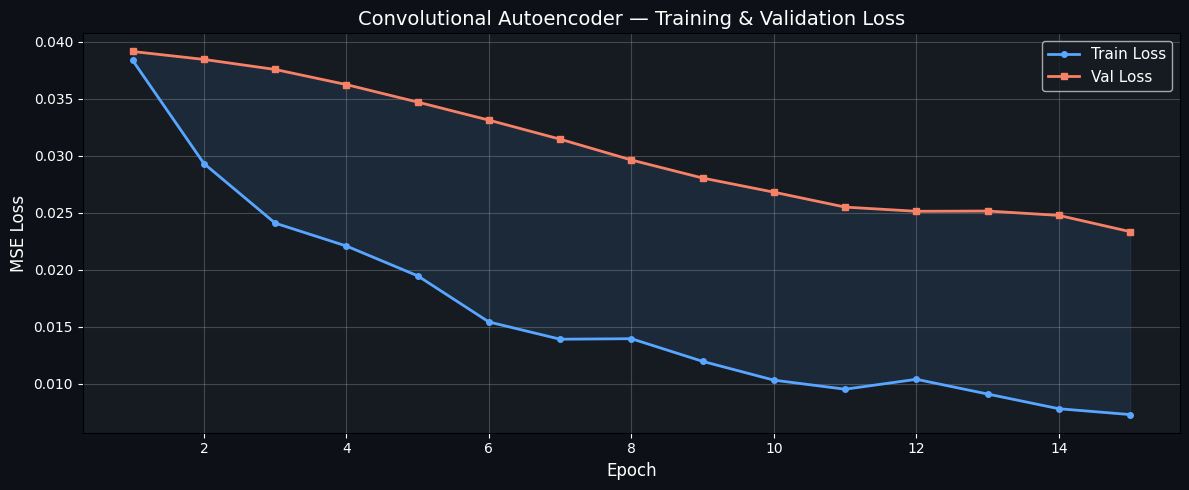

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
epochs_range = range(1, len(train_losses) + 1)
ax.plot(epochs_range, train_losses, '#58a6ff', linewidth=2, label='Train Loss', marker='o', markersize=4)
ax.plot(epochs_range, val_losses, '#f78166', linewidth=2, label='Val Loss', marker='s', markersize=4)
ax.fill_between(epochs_range, train_losses, val_losses, alpha=0.1, color='#58a6ff')
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('MSE Loss', fontsize=12)
ax.set_title('Convolutional Autoencoder — Training & Validation Loss', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../data/autoencoder_loss.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## Step 6: Reconstruction Quality Comparison

Latent feature shape: torch.Size([6, 256, 8, 8])  (B x C x H x W)


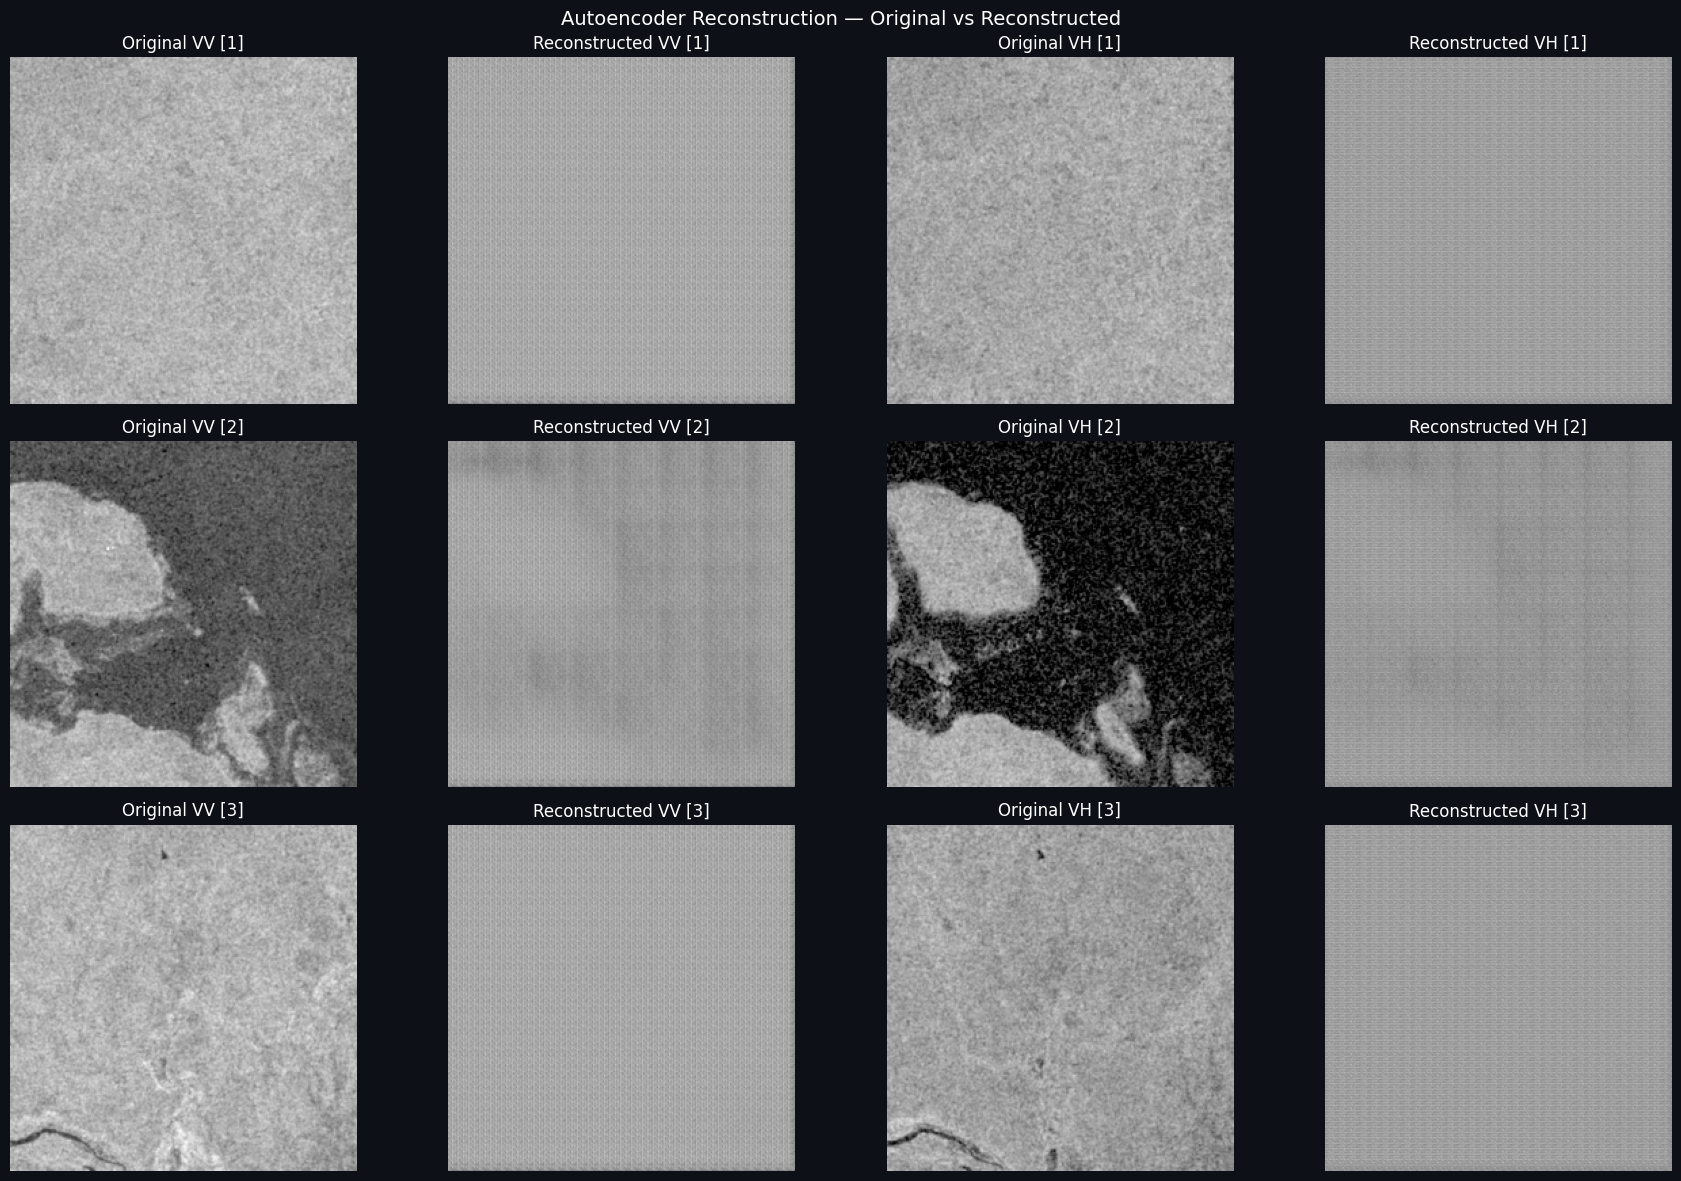

In [6]:
# Load best model
model.load_state_dict(torch.load('../models/best_autoencoder.pth', weights_only=True))
model.eval()

sample_batch, _ = next(iter(val_loader))
with torch.no_grad():
    reconstructed, latent = model(sample_batch.to(device))

sample_batch = sample_batch.cpu().numpy()
reconstructed = reconstructed.cpu().numpy()
print(f'Latent feature shape: {latent.shape}  (B x C x H x W)')

n_show = min(3, len(sample_batch))
fig, axes = plt.subplots(n_show, 4, figsize=(18, 4 * n_show))
fig.suptitle('Autoencoder Reconstruction — Original vs Reconstructed', fontsize=14, color='white')

for i in range(n_show):
    orig_vv = sample_batch[i, 0]
    orig_vh = sample_batch[i, 1]
    recon_vv = reconstructed[i, 0]
    recon_vh = reconstructed[i, 1]

    axes[i][0].imshow(orig_vv, cmap='gray', vmin=0, vmax=1)
    axes[i][0].set_title(f'Original VV [{i+1}]')
    axes[i][0].axis('off')

    axes[i][1].imshow(recon_vv, cmap='gray', vmin=0, vmax=1)
    axes[i][1].set_title(f'Reconstructed VV [{i+1}]')
    axes[i][1].axis('off')

    axes[i][2].imshow(orig_vh, cmap='gray', vmin=0, vmax=1)
    axes[i][2].set_title(f'Original VH [{i+1}]')
    axes[i][2].axis('off')

    axes[i][3].imshow(recon_vh, cmap='gray', vmin=0, vmax=1)
    axes[i][3].set_title(f'Reconstructed VH [{i+1}]')
    axes[i][3].axis('off')

plt.tight_layout()
plt.savefig('../data/autoencoder_reconstruction.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## Step 7: Latent Feature Map Visualization

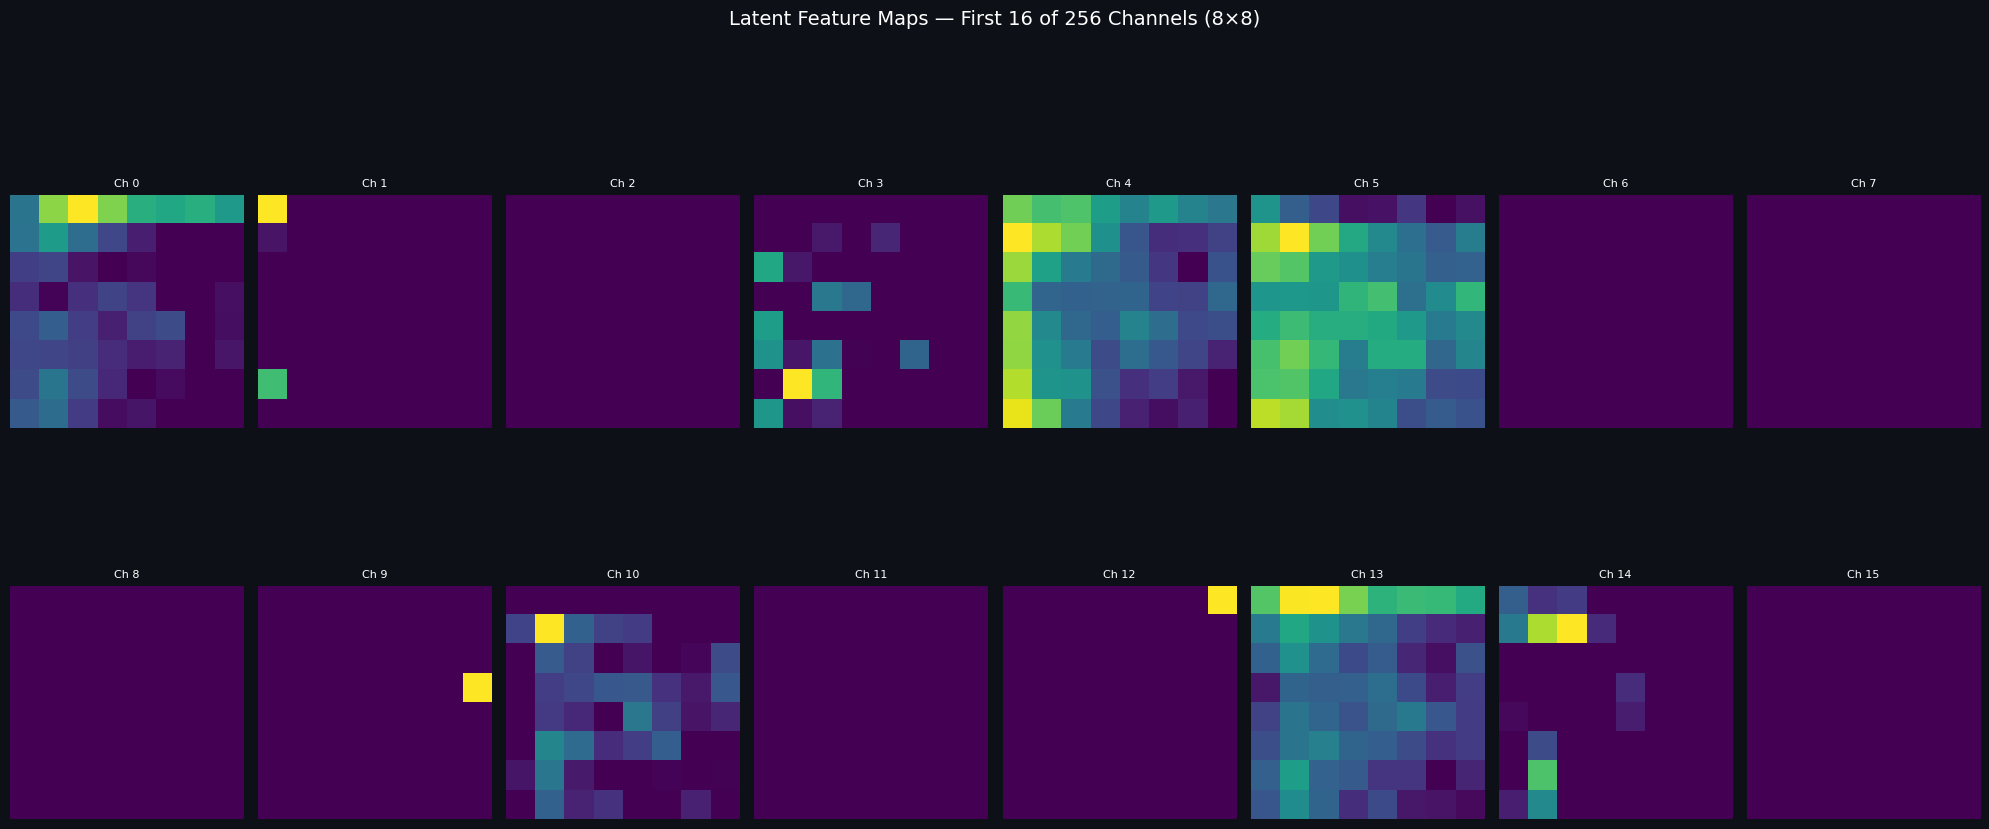

Encoder saved to ../models/encoder.pth


In [7]:
# Visualize first 16 channels of latent space
latent_np = latent[0].cpu().numpy()  # [256, 8, 8]
n_channels = min(16, latent_np.shape[0])
cols = 8
rows = (n_channels + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))
fig.suptitle(f'Latent Feature Maps — First {n_channels} of {latent_np.shape[0]} Channels (8×8)', fontsize=14, color='white')

for i in range(rows * cols):
    ax = axes[i // cols][i % cols]
    if i < n_channels:
        ax.imshow(latent_np[i], cmap='viridis')
        ax.set_title(f'Ch {i}', fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.savefig('../data/latent_features.png', dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print(f'Encoder saved to ../models/encoder.pth')
